In [1]:
from google.colab import files
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import csv
data = pd.read_csv('/content/17_study_performance.csv', quoting=csv.QUOTE_NONE)

In [3]:
data.head()

,"""gender""","""race_ethnicity""","""parental_level_of_education""","""lunch""","""test_preparation_course""","""math_score""","""reading_score""","""writing_score"""
0,"""female""","""group B""","""bachelor's degree""","""standard""","""none""","""72""","""72""","""74"""
1,"""female""","""group C""","""some college""","""standard""","""completed""","""69""","""90""","""88"""
2,"""female""","""group B""","""master's degree""","""standard""","""none""","""90""","""95""","""93"""
3,"""male""","""group A""","""associate's degree""","""free/reduced""","""none""","""47""","""57""","""44"""
4,"""male""","""group C""","""some college""","""standard""","""none""","""76""","""78""","""75"""


In [4]:
data.tail()

,"""gender""","""race_ethnicity""","""parental_level_of_education""","""lunch""","""test_preparation_course""","""math_score""","""reading_score""","""writing_score"""
995,"""female""","""group E""","""master's degree""","""standard""","""completed""","""88""","""99""","""95"""
996,"""male""","""group C""","""high school""","""free/reduced""","""none""","""62""","""55""","""55"""
997,"""female""","""group C""","""high school""","""free/reduced""","""completed""","""59""","""71""","""65"""
998,"""female""","""group D""","""some college""","""standard""","""completed""","""68""","""78""","""77"""
999,"""female""","""group D""","""some college""","""free/reduced""","""none""","""77""","""86""","""86"""


In [5]:
data.shape

(1000, 8)

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   "gender"                       1000 non-null   object
 1   "race_ethnicity"               1000 non-null   object
 2   "parental_level_of_education"  1000 non-null   object
 3   "lunch"                        1000 non-null   object
 4   "test_preparation_course"      1000 non-null   object
 5   "math_score"                   1000 non-null   object
 6   "reading_score"                1000 non-null   object
 7   "writing_score"                1000 non-null   object
dtypes: object(8)
memory usage: 62.6+ KB


In [7]:
data.isnull().sum()

,0
"""gender""",0
"""race_ethnicity""",0
"""parental_level_of_education""",0
"""lunch""",0
"""test_preparation_course""",0
"""math_score""",0
"""reading_score""",0
"""writing_score""",0


In [8]:
data.isnull().sum()

,0
"""gender""",0
"""race_ethnicity""",0
"""parental_level_of_education""",0
"""lunch""",0
"""test_preparation_course""",0
"""math_score""",0
"""reading_score""",0
"""writing_score""",0


In [9]:
data.min(numeric_only=True)

,0


In [10]:
data.max(numeric_only=True)

,0


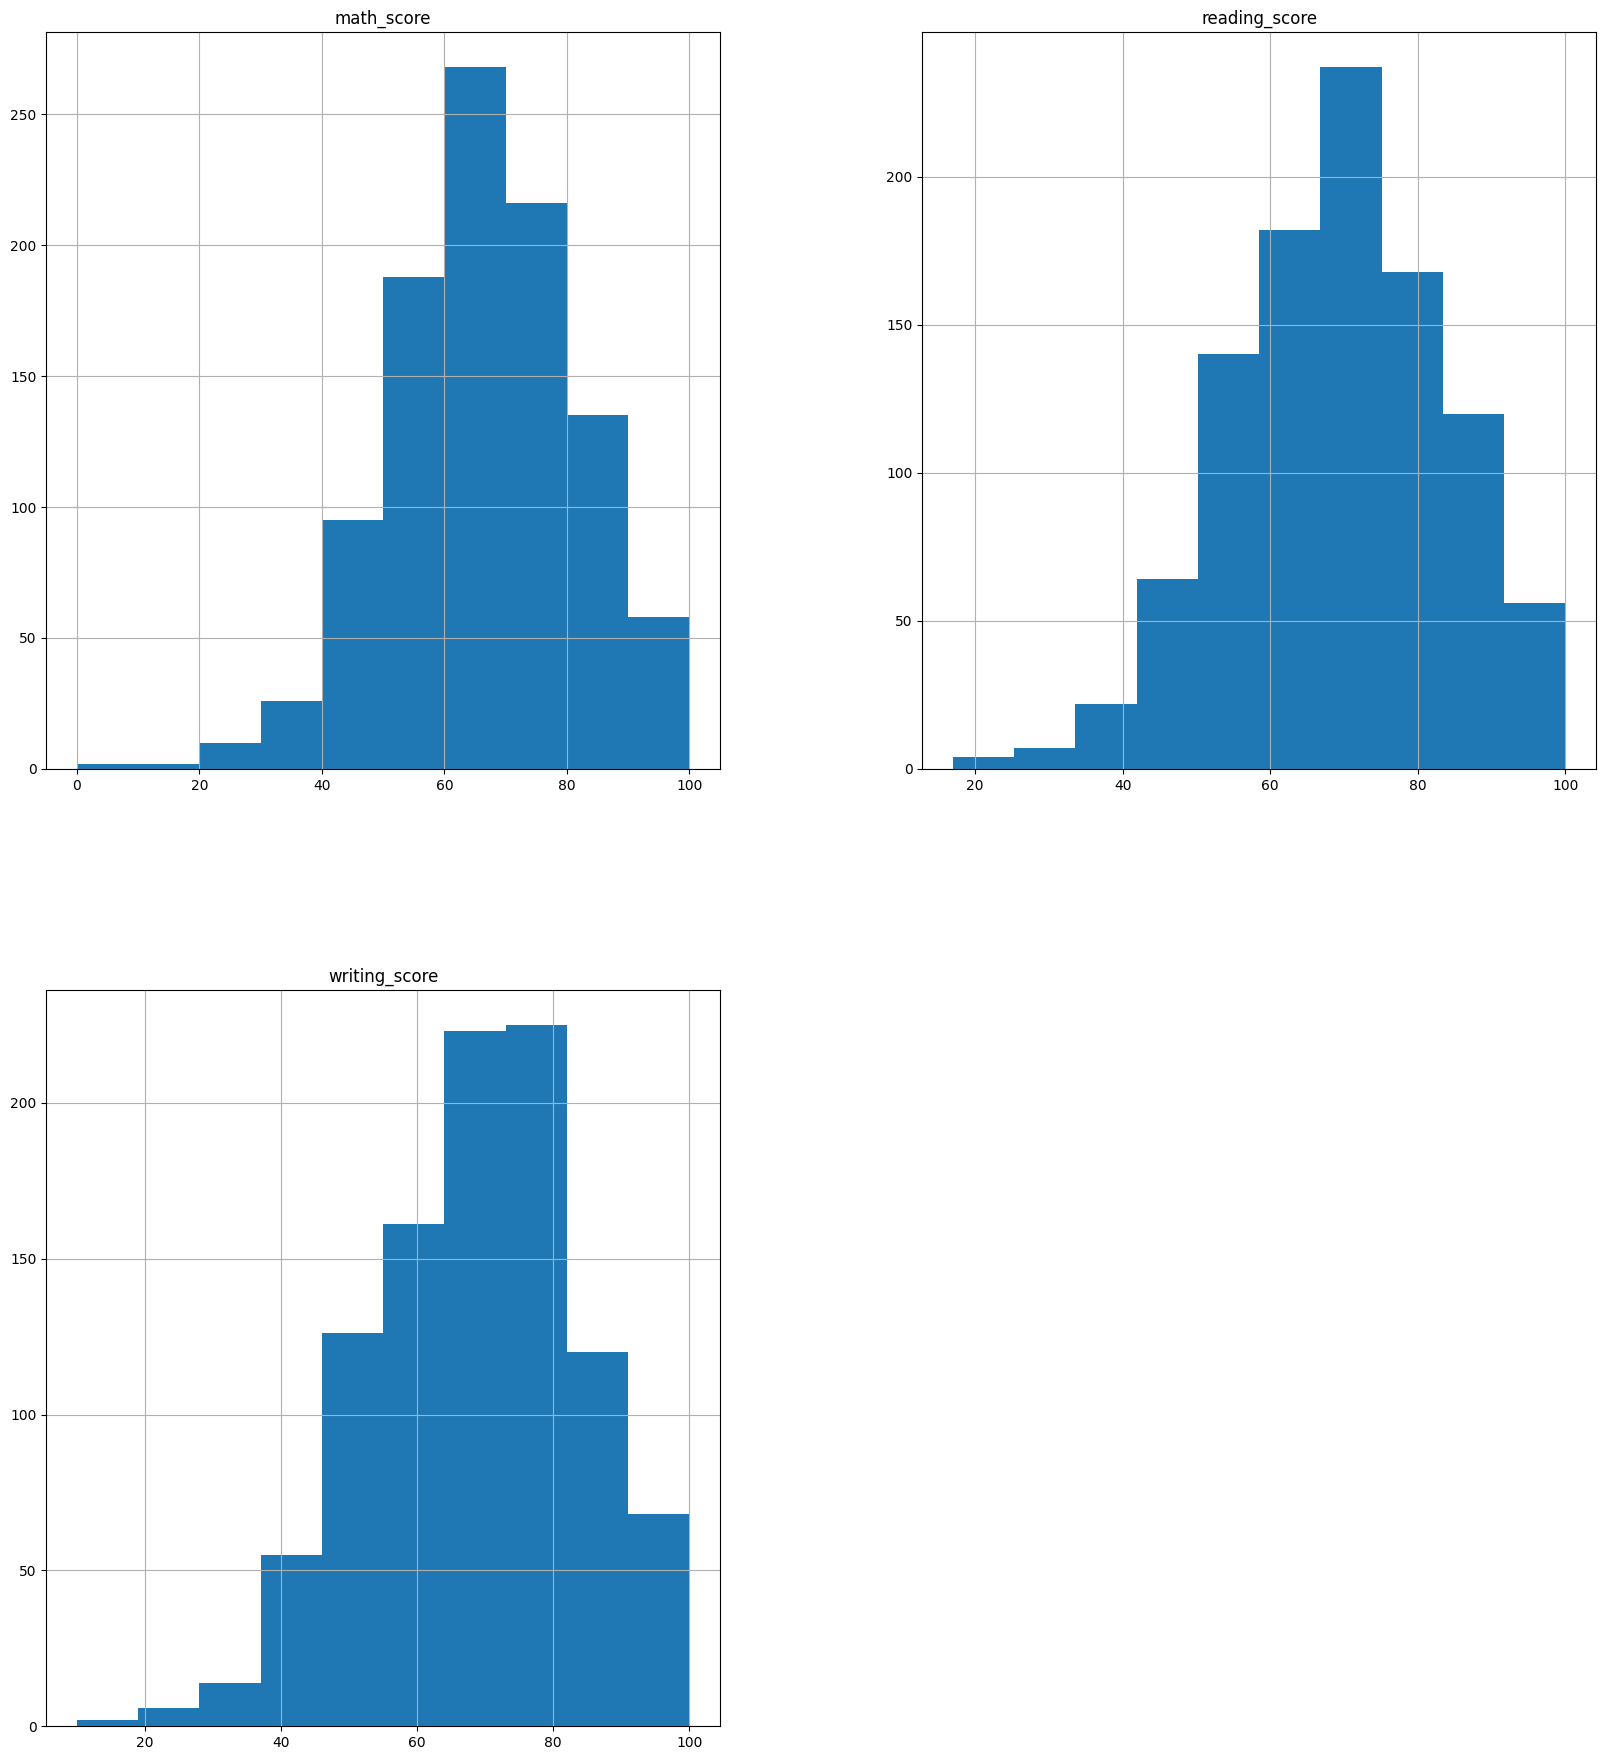

In [13]:
data.columns = data.columns.str.replace('"', '')
for col in data.columns:
    if data[col].dtype == 'object':
        data[col] = data[col].str.replace('"', '')

score_cols = ['math_score', 'reading_score', 'writing_score']
for col in score_cols:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors='coerce')

data.hist(figsize=(20, 22))
plt.show()

In [14]:
data.columns

Index(['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch',
       'test_preparation_course', 'math_score', 'reading_score',
       'writing_score'],
      dtype='object')

Correlation Matrix:


,math_score,reading_score,writing_score
math_score,1.000000,0.817580,0.802642
reading_score,0.817580,1.000000,0.954598
writing_score,0.802642,0.954598,1.000000


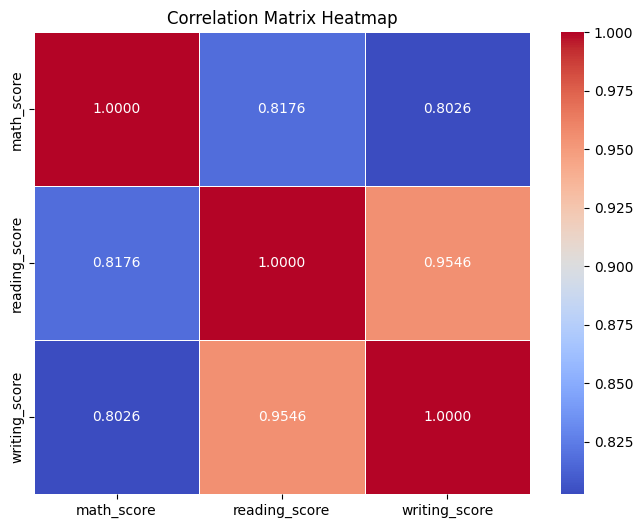

In [15]:
numeric_data = data.select_dtypes(include=[np.number])

correlation_matrix = numeric_data.corr()
print("Correlation Matrix:")
display(correlation_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.4f', linewidths=0.5)
plt.title('Correlation Matrix Heatmap')
plt.show()

In [16]:
correlation_matrix = data[['math_score', 'reading_score', 'writing_score']].corr()
print("Correlation Matrix:")
display(correlation_matrix)

def get_correlation(col1, col2):
    corr_val = data[col1].corr(data[col2])
    print(f"Correlation between '{col1}' and '{col2}': {corr_val:.4f}")
    return corr_val

get_correlation('math_score', 'reading_score')

Correlation Matrix:


,math_score,reading_score,writing_score
math_score,1.000000,0.817580,0.802642
reading_score,0.817580,1.000000,0.954598
writing_score,0.802642,0.954598,1.000000


Correlation between 'math_score' and 'reading_score': 0.8176


np.float64(0.8175796636720546)

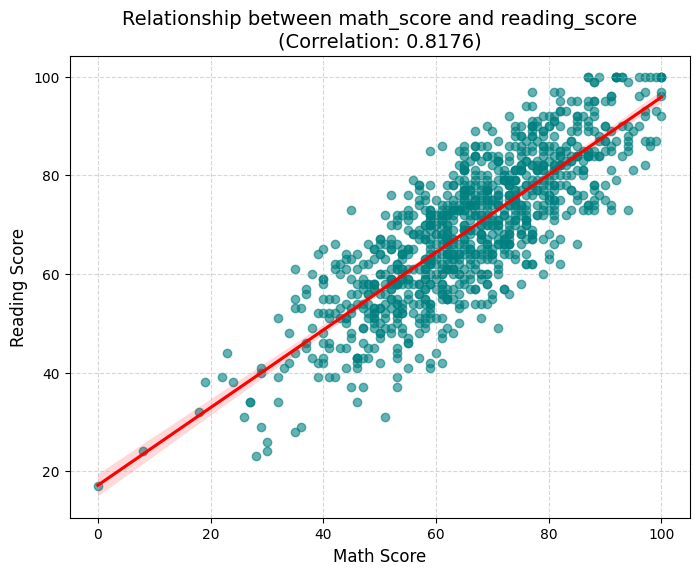

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_correlation(col1, col2):
    corr_value = data[col1].corr(data[col2])

    plt.figure(figsize=(8, 6))
    sns.regplot(data=data, x=col1, y=col2, scatter_kws={'alpha':0.6, 'color':'teal'}, line_kws={'color':'red'})

    plt.title(f'Relationship between {col1} and {col2}\n(Correlation: {corr_value:.4f})', fontsize=14)
    plt.xlabel(col1.replace('_', ' ').title(), fontsize=12)
    plt.ylabel(col2.replace('_', ' ').title(), fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

plot_correlation('math_score', 'reading_score')

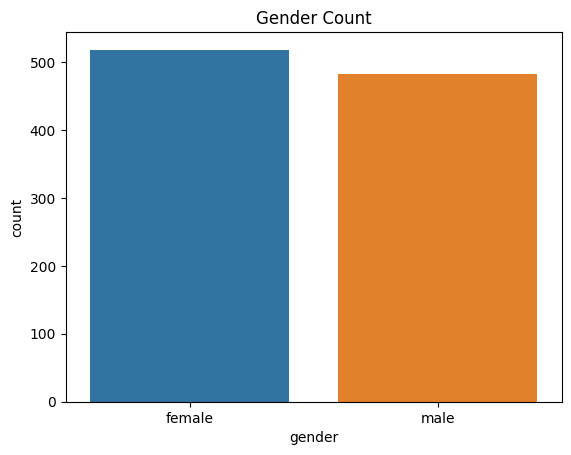

In [19]:
sns.countplot(x='gender', hue='gender', data=data)
plt.title('Gender Count')
plt.show()

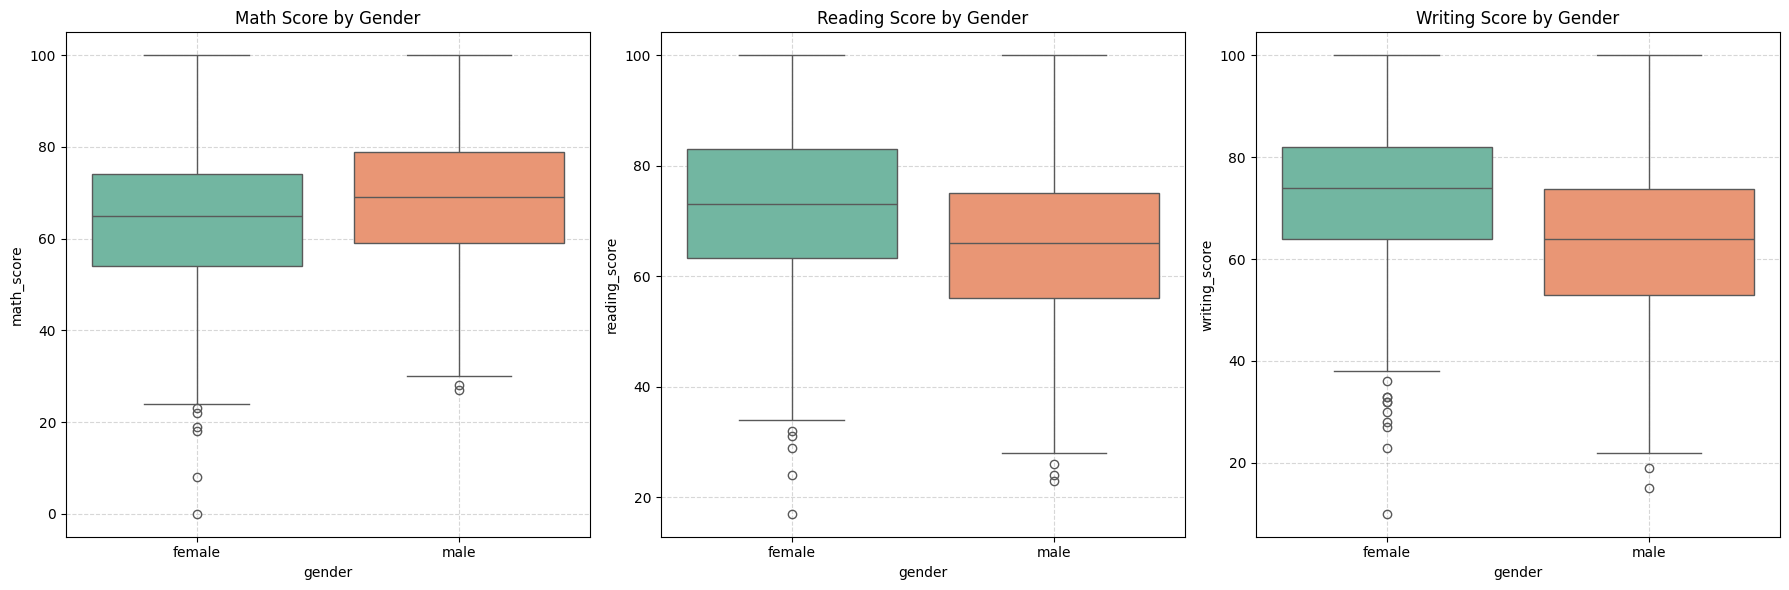

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
sns.boxplot(ax=axes[0], x='gender', y='math_score', data=data, palette='Set2', hue='gender', legend=False)
axes[0].set_title('Math Score by Gender')
axes[0].grid(True, linestyle='--', alpha=0.5)

sns.boxplot(ax=axes[1], x='gender', y='reading_score', data=data, palette='Set2', hue='gender', legend=False)
axes[1].set_title('Reading Score by Gender')
axes[1].grid(True, linestyle='--', alpha=0.5)

sns.boxplot(ax=axes[2], x='gender', y='writing_score', data=data, palette='Set2', hue='gender', legend=False)
axes[2].set_title('Writing Score by Gender')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

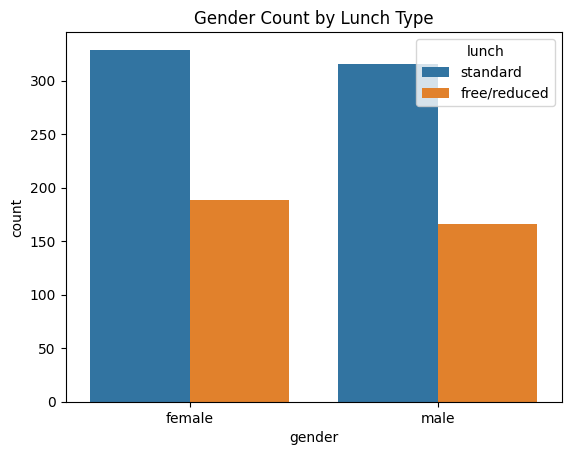

In [23]:
sns.countplot(x='gender', hue='lunch', data=data)
plt.title('Gender Count by Lunch Type')
plt.show()

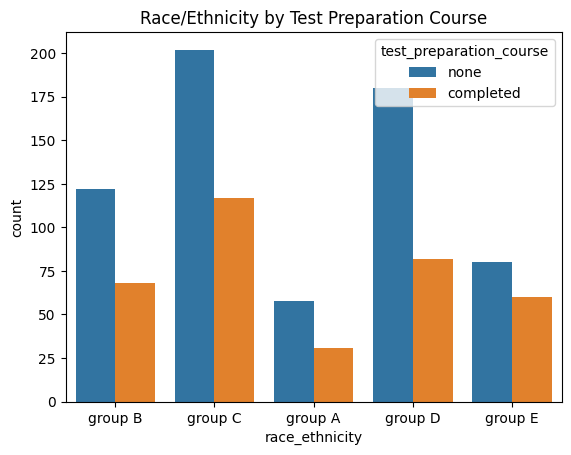

In [25]:
sns.countplot(x='race_ethnicity', hue='test_preparation_course', data=data)
plt.title('Race/Ethnicity by Test Preparation Course')
plt.show()

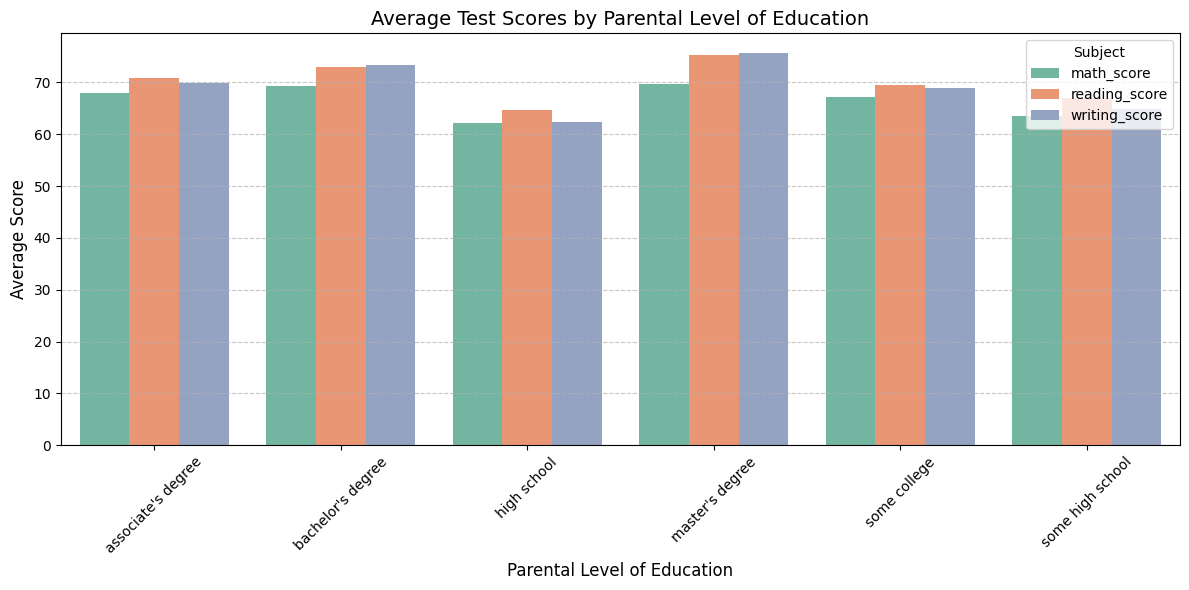

In [26]:
education_scores = data.groupby('parental_level_of_education')[['math_score', 'reading_score', 'writing_score']].mean().reset_index()

education_scores_melted = education_scores.melt(id_vars='parental_level_of_education', var_name='Subject', value_name='Average Score')

plt.figure(figsize=(12, 6))
sns.barplot(data=education_scores_melted, x='parental_level_of_education', y='Average Score', hue='Subject', palette='Set2')
plt.title('Average Test Scores by Parental Level of Education', fontsize=14)
plt.xlabel('Parental Level of Education', fontsize=12)
plt.ylabel('Average Score', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()